# Amazon Sales Analysis

**Status: in progress.** Exploratory business analysis of Amazon order data (3,203 orders, western US states):
sales and profit over time, category profitability, geography, and customer segmentation (RFM + K-Means).

**Business questions**
1. How do sales and profit evolve over time, and how fast are orders shipped?
2. Which product categories drive sales, and which ones are actually profitable (profit margin, unit price)?
3. Where do orders come from?
4. Which customers are most valuable, and what customer segments exist?

**Dataset:** [Amazon Sales Dataset on Kaggle](https://www.kaggle.com/datasets/anandshaw2001/amazon-sales-dataset).
Download `Amazon 2_Raw.xlsx` and place it in a `data/` folder next to this notebook.

## Contents
1. [Setup and loading](#setup)
2. [Pre-processing](#pre)
3. [Sales and profit over time](#time)
4. [Category analysis](#cat)
5. [Geography](#geo)
6. [Customer analysis: RFM and K-Means](#cust)
7. [Key findings](#findings)
8. [Limitations and next steps](#next)

## 1. Setup and loading<a name=setup></a>

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

In [84]:
DATA_PATH = "data/Amazon 2_Raw.xlsx"   # see README for the download link
df = pd.read_excel(DATA_PATH)
print(df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head(3)

(3203, 10)
Missing values: 0


,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,6.87
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.86,7,14.17
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.28,4,1.97


## 2. Pre-processing<a name=pre></a>
- Convert the date columns to `datetime`.
- Split `Geography` into country, city, and state.
- Create a `CustomerID` from the e-mail prefix, then drop the raw e-mail (keeps the notebook free of personal-looking data).
- Add derived columns: `Month`, `ShipDays`, `Margin` (profit / sales) and `UnitPrice` (sales / quantity).

In [85]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

geo = df["Geography"].str.split(",", expand=True)
df["Country"] = geo[0].str.strip()
df["City"] = geo[1].str.strip()
df["State"] = geo[2].str.strip()

df["CustomerID"] = df["EmailID"].str.split("@").str[0]
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["ShipDays"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Margin"] = df["Profit"] / df["Sales"]
df["UnitPrice"] = df["Sales"] / df["Quantity"]

df = df.drop(columns=["EmailID", "Geography"])   # keep Order ID: needed for purchase frequency
df[["Order Date", "State", "Category", "Sales", "Profit", "Quantity", "ShipDays"]].describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order Date,3203,NaN,NaN,NaN,2013-05-10 03:06:07.530440192,2011-01-07 00:00:00,2012-05-22 00:00:00,2013-07-22 00:00:00,2014-05-23 00:00:00,2014-12-31 00:00:00,NaN
State,3203,11,California,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3203,17,Binders,471,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales,"3,203.00",NaN,NaN,NaN,226.49,0.99,19.44,60.84,215.81,"13,999.96",524.88
Profit,"3,203.00",NaN,NaN,NaN,33.85,"-3,399.98",3.85,11.17,33.00,"6,719.98",174.11
Quantity,"3,203.00",NaN,NaN,NaN,3.83,1.00,2.00,3.00,5.00,14.00,2.26
ShipDays,"3,203.00",NaN,NaN,NaN,3.93,0.00,3.00,4.00,5.00,7.00,1.81


In [86]:
df.head(2)

,Order ID,Order Date,Ship Date,Category,Product Name,Sales,Quantity,Profit,Country,City,State,CustomerID,Month,ShipDays,Margin,UnitPrice
0,CA-2013-138688,2013-06-13,2013-06-17,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,6.87,United States,Los Angeles,California,DarrinVanHuff,2013-06-01,4,0.47,7.31
1,CA-2011-115812,2011-06-09,2011-06-14,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.86,7,14.17,United States,Los Angeles,California,BrosinaHoffman,2011-06-01,5,0.29,6.98


## 3. Sales and profit over time<a name=time></a>

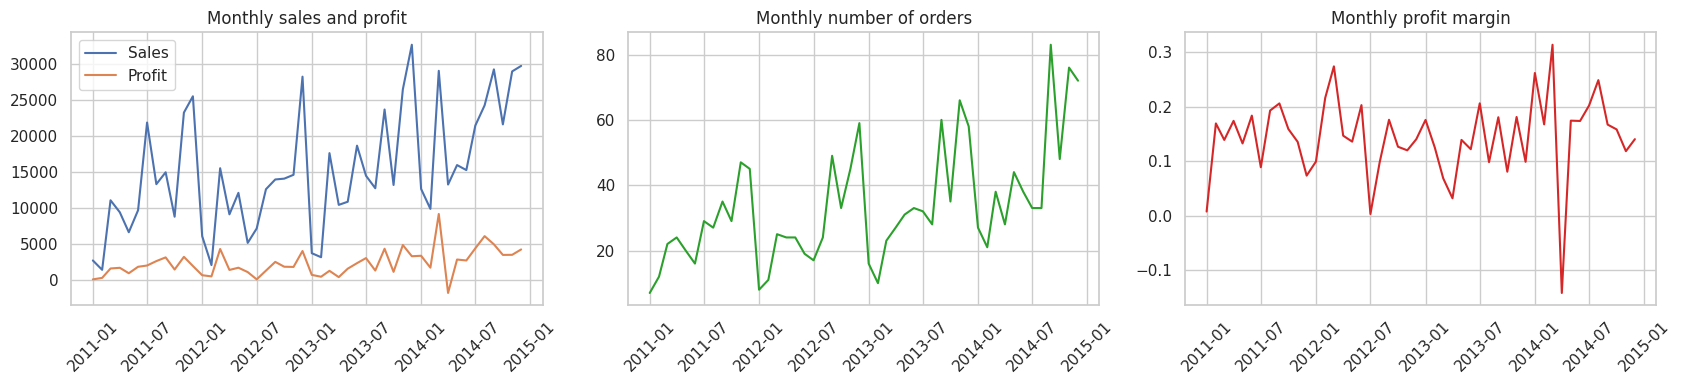

In [87]:
monthly = (df.groupby("Month")
             .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
             .reset_index())
monthly["Margin"] = monthly["Profit"] / monthly["Sales"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(monthly["Month"], monthly["Sales"], label="Sales")
axes[0].plot(monthly["Month"], monthly["Profit"], label="Profit")
axes[0].set_title("Monthly sales and profit"); axes[0].legend()
axes[1].plot(monthly["Month"], monthly["Orders"], color="tab:green")
axes[1].set_title("Monthly number of orders")
axes[2].plot(monthly["Month"], monthly["Margin"], color="tab:red")
axes[2].set_title("Monthly profit margin")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [88]:
yearly = (df.assign(Year=df["Order Date"].dt.year)
            .groupby("Year")
            .agg(Orders=("Order ID", "nunique"), Sales=("Sales", "sum"), Profit=("Profit", "sum")))
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly

,Orders,Sales,Profit,Margin
Year,,,,
2011,313,"147,883.03","20,065.69",0.14
2012,338,"139,966.25","20,492.19",0.15
2013,419,"186,976.02","23,959.94",0.13
2014,541,"250,632.53","43,900.63",0.18


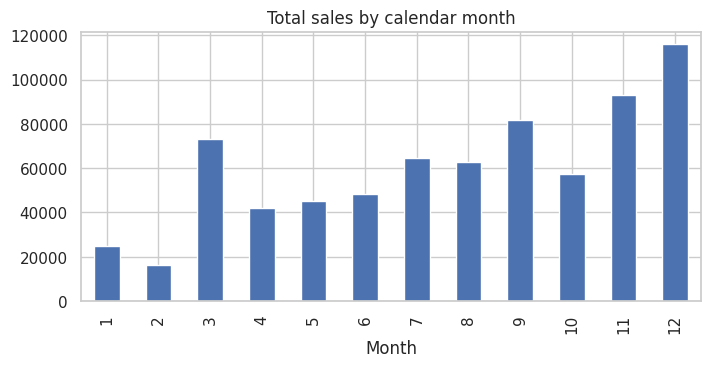

ShipDays
0    166
1    159
2    450
3    308
4    832
5    689
6    361
7    238
Name: count, dtype: int64


In [89]:
# Seasonality: average sales by calendar month
season = df.groupby(df["Order Date"].dt.month)["Sales"].sum()
ax = season.plot.bar(figsize=(8, 3.5), title="Total sales by calendar month")
ax.set_xlabel("Month")
plt.show()

# Shipping time
print(df["ShipDays"].value_counts().sort_index())

## 4. Category analysis<a name=cat></a>

In [90]:
cat = (df.groupby("Category")
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
              Quantity=("Quantity", "sum"), Orders=("Order ID", "nunique")))
cat["Margin"] = cat["Profit"] / cat["Sales"]
cat["AvgUnitPrice"] = cat["Sales"] / cat["Quantity"]
cat = cat.sort_values("Sales", ascending=False)
cat

,Sales,Profit,Quantity,Orders,Margin,AvgUnitPrice
Category,,,,,,
Chairs,"101,781.33","4,027.58",734,191,0.04,138.67
Phones,"98,684.35","9,110.74",1066,256,0.09,92.57
Tables,"84,754.56","1,482.61",481,114,0.02,176.20
Storage,"70,532.85","8,645.32",1039,247,0.12,67.89
Accessories,"61,114.12","16,484.60",1032,236,0.27,59.22
Binders,"55,961.11","16,096.80",1868,403,0.29,29.96
Copiers,"49,749.24","19,327.24",88,25,0.39,565.33
Machines,"42,444.12",-618.93,147,39,-0.01,288.74
Bookcases,"36,004.12","-1,646.51",306,79,-0.05,117.66


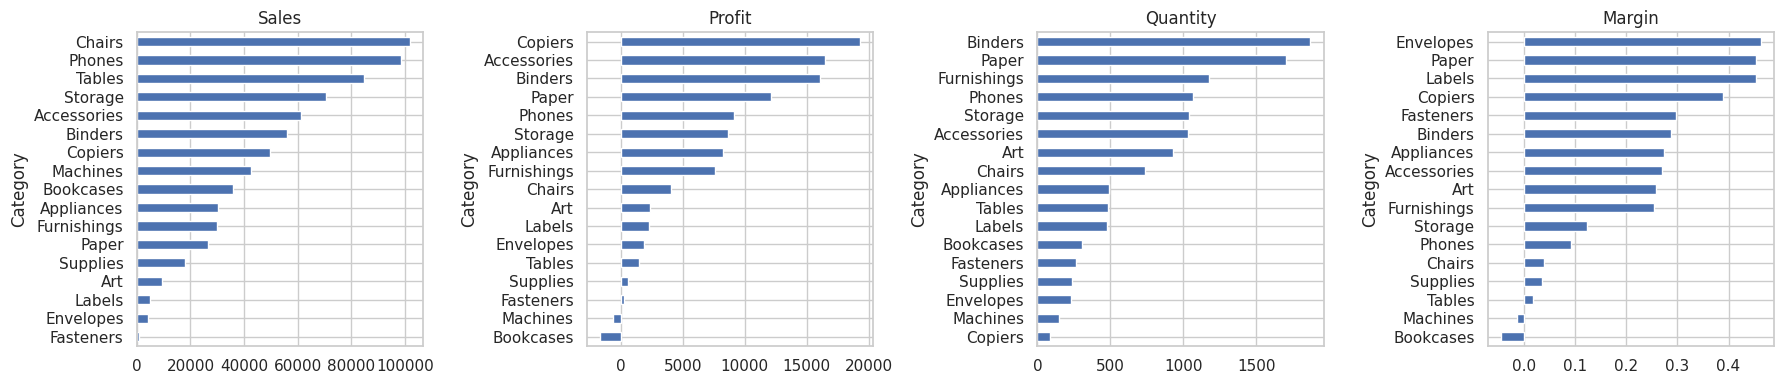

In [91]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Sales", "Profit", "Quantity", "Margin"]):
    cat[col].sort_values().plot.barh(ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Price and quantity (exploratory).** A first look at whether higher-priced products are bought in smaller quantities.
This is only descriptive: with no discount or competitor data it is *not* a price-elasticity estimate.

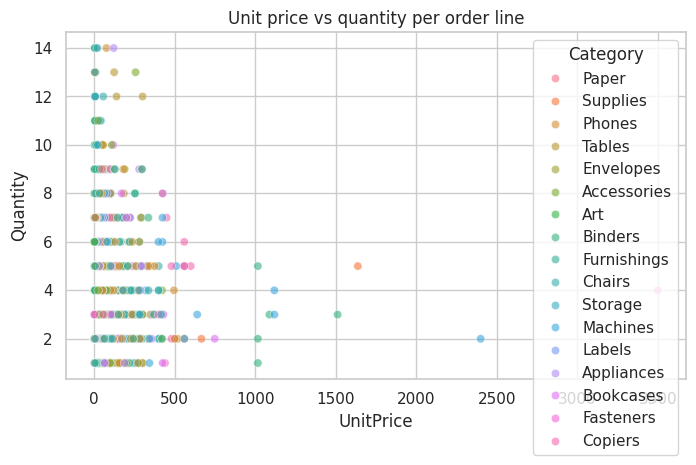

           UnitPrice  Quantity  Sales  Profit  Margin
UnitPrice       1.00     -0.02   0.93    0.55   -0.40
Quantity       -0.02      1.00   0.34    0.31   -0.02
Sales           0.93      0.34   1.00    0.63   -0.38
Profit          0.55      0.31   0.63    1.00    0.28
Margin         -0.40     -0.02  -0.38    0.28    1.00


In [92]:
sample = df.sample(min(len(df), 2000), random_state=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=sample, x="UnitPrice", y="Quantity", hue="Category", alpha=0.6, ax=ax)
ax.set_title("Unit price vs quantity per order line")
plt.show()

print(df[["UnitPrice", "Quantity", "Sales", "Profit", "Margin"]].corr(method="spearman").round(2))

## 5. Geography<a name=geo></a>

,Sales,Profit,Orders,Margin
State,,,,
California,"457,687.63","76,381.39",1021,0.17
Washington,"138,641.27","33,402.65",256,0.24
Arizona,"35,282.00","-3,427.92",108,-0.10
Colorado,"32,108.12","-6,527.86",79,-0.20
Oregon,"17,431.15","-1,190.47",56,-0.07
Nevada,"16,729.10","3,316.77",23,0.20
Utah,"11,220.06","2,546.53",26,0.23
Montana,"5,589.35","1,833.33",8,0.33
New Mexico,"4,783.52","1,157.12",22,0.24


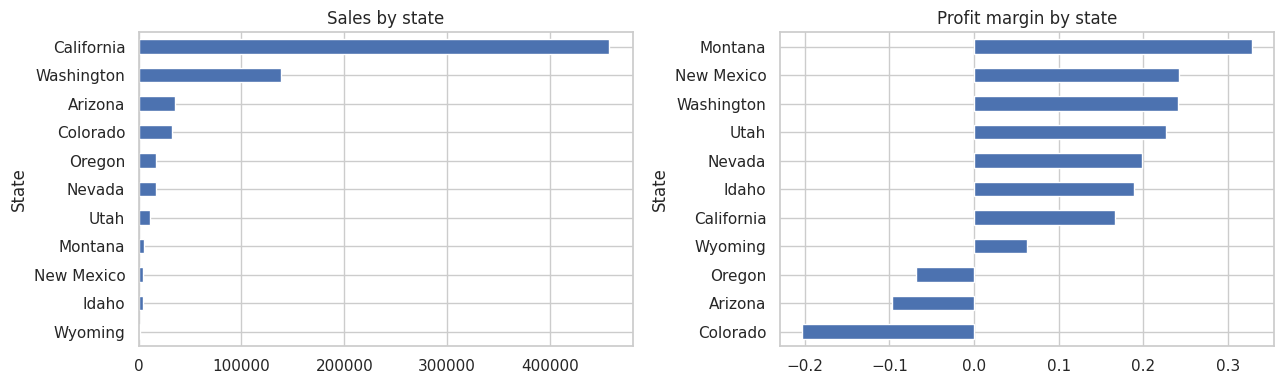

In [93]:
state = (df.groupby("State")
           .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique")))
state["Margin"] = state["Profit"] / state["Sales"]
state = state.sort_values("Sales", ascending=False)
display(state)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
state["Sales"].sort_values().plot.barh(ax=axes[0], title="Sales by state")
state["Margin"].sort_values().plot.barh(ax=axes[1], title="Profit margin by state")
plt.tight_layout(); plt.show()

## 6. Customer analysis: RFM and K-Means<a name=cust></a>
**RFM** describes each customer with three numbers:
- **Recency**: days since the last order (lower is better),
- **Frequency**: number of distinct orders,
- **Monetary**: total sales.

Each is scored from 1 to 5 by quintile (ranks are used so ties do not break the binning), and customers are
grouped into simple, interpretable segments. A proper customer lifetime value (CLTV) model needs retention
modelling and more history than this dataset offers, so it is left for later.

In [94]:
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)

rfm = (df.groupby("CustomerID")
         .agg(Recency=("Order Date", lambda s: (snapshot - s.max()).days),
              Frequency=("Order ID", "nunique"),
              Monetary=("Sales", "sum"),
              Profit=("Profit", "sum"))
         .reset_index())

def quintile_score(series, high_is_good=True):
    ranked = series.rank(method="first", ascending=high_is_good)
    return pd.qcut(ranked, 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["R"] = quintile_score(rfm["Recency"], high_is_good=False)   # recent = high score
rfm["F"] = quintile_score(rfm["Frequency"])
rfm["M"] = quintile_score(rfm["Monetary"])

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.F >= 4:              return "Loyal"
    if r.R <= 2 and r.F >= 3: return "At risk"
    if r.R <= 2:              return "Inactive"
    return "Potential"

rfm["Segment"] = rfm.apply(segment, axis=1)
print("Customers:", len(rfm))
rfm.head()

Customers: 686


,CustomerID,Recency,Frequency,Monetary,Profit,R,F,M,Segment
0,AaronBergman,1396,1,309.59,15.00,1,1,2,Inactive
1,AaronHawkins,735,3,"1,328.12",179.88,1,4,4,Loyal
2,AaronSmayling,89,3,737.03,19.15,4,4,3,Champions
3,AdamBellavance,55,3,"2,693.92",363.78,5,4,5,Champions
4,AdamHart,260,3,463.77,99.28,3,4,3,Loyal


,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalSales,TotalProfit,SalesShare
Segment,,,,,,,
Champions,155,69.14,3.78,"1,588.32","246,190.23","39,707.96",0.34
Loyal,119,412.20,3.45,"1,608.65","191,429.59","28,286.06",0.26
Potential,196,152.26,1.63,895.79,"175,575.51","26,848.20",0.24
Inactive,167,834.18,1.18,456.95,"76,310.36","8,494.06",0.11
At risk,49,644.94,2.00,733.72,"35,952.13","5,082.17",0.05


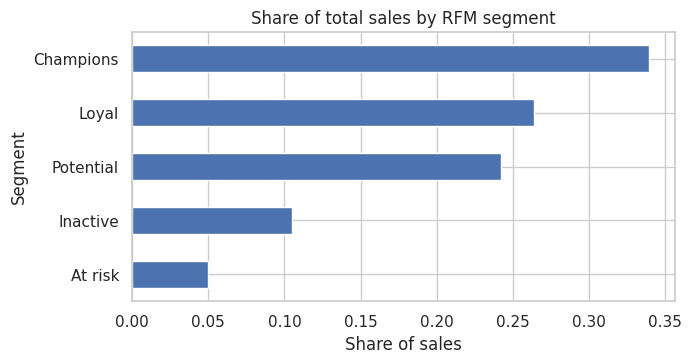

In [95]:
seg = (rfm.groupby("Segment")
          .agg(Customers=("CustomerID", "count"), AvgRecency=("Recency", "mean"),
               AvgFrequency=("Frequency", "mean"), AvgMonetary=("Monetary", "mean"),
               TotalSales=("Monetary", "sum"), TotalProfit=("Profit", "sum"))
          .sort_values("TotalSales", ascending=False))
seg["SalesShare"] = seg["TotalSales"] / seg["TotalSales"].sum()
display(seg)

ax = seg["SalesShare"].sort_values().plot.barh(figsize=(7, 3.5), title="Share of total sales by RFM segment")
ax.set_xlabel("Share of sales")
plt.show()

### K-Means clustering on RFM
Instead of hand-written rules, K-Means finds the groups from the data. Features are log-transformed (they are
right-skewed) and standardized. The number of clusters is chosen with the silhouette score.

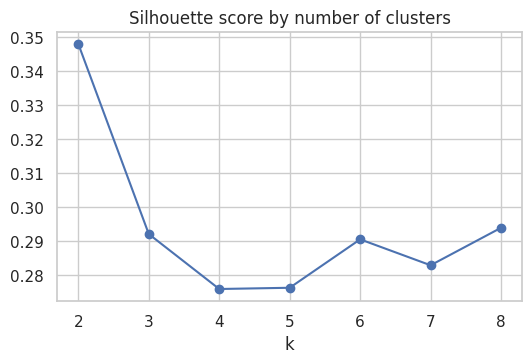

Chosen K: 2


In [96]:
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
X_scaled = StandardScaler().fit_transform(X)

sil = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    sil[k] = silhouette_score(X_scaled, labels)

ax = pd.Series(sil).plot(marker="o", figsize=(6, 3.5), title="Silhouette score by number of clusters")
ax.set_xlabel("k"); plt.show()


K = max(sil, key=sil.get)
print("Chosen K:", K)

,Customers,Recency,Frequency,Monetary,Profit
Cluster,,,,,
0,256,395.36,2.69,"1,600.95",245.84
1,181,53.41,3.38,"1,396.78",207.99
2,249,600.97,1.24,252.20,31.48


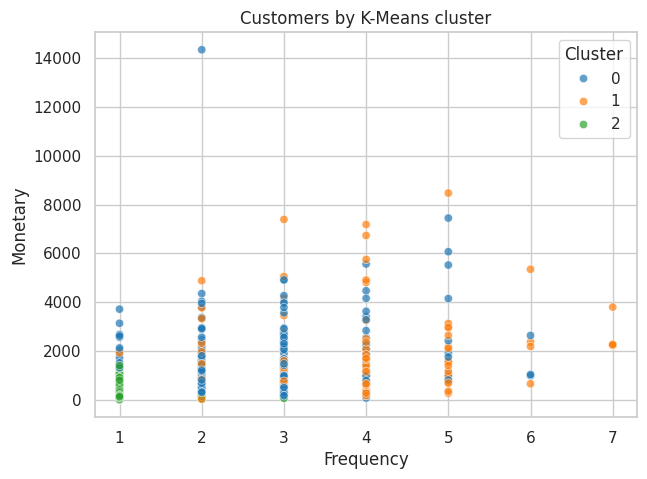

In [97]:
K=3
rfm["Cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_scaled)

profile = (rfm.groupby("Cluster")
              .agg(Customers=("CustomerID", "count"), Recency=("Recency", "mean"),
                   Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean"),
                   Profit=("Profit", "mean")))
display(profile)

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster", palette="tab10", alpha=0.7, ax=ax)
ax.set_title("Customers by K-Means cluster")
plt.show()

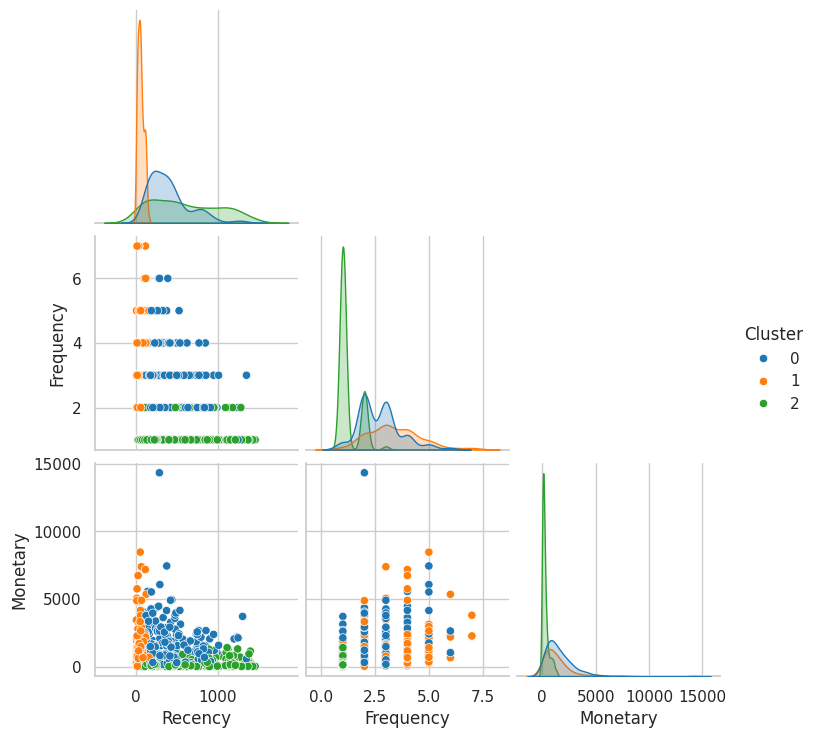

In [98]:
sns.pairplot(rfm, vars=["Recency", "Frequency", "Monetary"], hue="Cluster", palette="tab10", corner=True)
plt.show()

Silhouette is highest for `k=2 (≈0.35)`, drops to `≈0.29` for `k=3`, and stays roughly flat up to `k=8`, so the data show a moderate structure rather than sharply separated groups. I chose `k=3` over `k=2` because it splits repeat buyers into active and lapsing customers (see the pair plot), a distinction that matters for retention actions, at a small cost in silhouette. `k=2` would only separate one-time from repeat customers.

In [99]:
cluster_names = {
    0: "Lapsing repeat buyers",
    1: "Active loyal",
    2: "One-time / inactive",
}
rfm["ClusterName"] = rfm["Cluster"].map(cluster_names)

profile_named = (rfm.groupby("ClusterName")
                    .agg(Customers=("CustomerID", "count"), Recency=("Recency", "mean"),
                         Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean")))
profile_named["Share"] = profile_named["Customers"] / profile_named["Customers"].sum()
profile_named

,Customers,Recency,Frequency,Monetary,Share
ClusterName,,,,,
Active loyal,181,53.41,3.38,"1,396.78",0.26
Lapsing repeat buyers,256,395.36,2.69,"1,600.95",0.37
One-time / inactive,249,600.97,1.24,252.20,0.36


In [100]:
df.nsmallest(10, "Profit")

,Order ID,Order Date,Ship Date,Category,Product Name,Sales,Quantity,Profit,Country,City,State,CustomerID,Month,ShipDays,Margin,UnitPrice
969,CA-2014-134845,2014-04-18,2014-04-24,Machines,Lexmark MX611dhe Monochrome Laser Printer,"2,549.99",5,"-3,399.98",United States,Louisville,Colorado,SharelleRoach,2014-04-01,6,-1.33,510.00
2487,US-2013-157490,2013-10-07,2013-10-08,Machines,Zebra GK420t Direct Thermal/Thermal Transfer P...,703.71,6,-938.28,United States,Pueblo,Colorado,LaurelBeltran,2013-10-01,1,-1.33,117.29
134,CA-2013-109869,2013-04-23,2013-04-30,Tables,Bush Advantage Collection Racetrack Conference...,"1,272.63",6,-814.48,United States,Phoenix,Arizona,TanjaNorvell,2013-04-01,7,-0.64,212.11
413,US-2012-103471,2012-12-24,2012-12-28,Bookcases,"Atlantic Metals Mobile 4-Shelf Bookcases, Cust...",590.06,7,-786.74,United States,Colorado Springs,Colorado,JimRadford,2012-12-01,4,-1.33,84.29
2960,CA-2011-148383,2011-12-27,2011-12-31,Binders,GBC DocuBind 300 Electric Binding Machine,946.76,6,-694.29,United States,Phoenix,Arizona,ResiPÃ¶lking,2011-12-01,4,-0.73,157.79
2363,CA-2014-159282,2014-10-17,2014-10-22,Machines,Swingline SM12-08 MicroCut Jam Free Shredder,599.99,5,-479.99,United States,Yuma,Arizona,GaryHansen,2014-10-01,5,-0.80,120.00
570,US-2013-100839,2013-10-14,2013-10-18,Tables,Hon 5100 Series Wood Tables,727.45,5,-465.57,United States,Aurora,Colorado,NoahChilds,2013-10-01,4,-0.64,145.49
1185,US-2011-169789,2011-12-30,2012-01-04,Binders,Ibico Ibimaster 300 Manual Binding System,551.99,5,-459.99,United States,Phoenix,Arizona,MaureenFritzler,2011-12-01,5,-0.83,110.40
1235,US-2014-142573,2014-07-19,2014-07-24,Tables,"Chromcraft 48"" x 96"" Racetrack Double Pedestal...",801.60,5,-448.90,United States,Phoenix,Arizona,MarisLaWare,2014-07-01,5,-0.56,160.32
2192,CA-2013-109827,2013-12-26,2014-01-02,Machines,Panasonic KX MC6040 Color Laser Multifunction ...,269.97,2,-386.96,United States,Phoenix,Arizona,LaurelWorkman,2013-12-01,7,-1.43,134.99


In [101]:
worst = df.nsmallest(10, "Profit")[["State", "Category", "Sales", "Profit"]]
display(worst)

# State profit with and without the 10 largest-loss order lines
with_all = df.groupby("State")["Profit"].sum()
without_worst = df.drop(worst.index).groupby("State")["Profit"].sum()
pd.DataFrame({"Profit": with_all, "Profit_excl_10_worst": without_worst}).sort_values("Profit")

,State,Category,Sales,Profit
969,Colorado,Machines,"2,549.99","-3,399.98"
2487,Colorado,Machines,703.71,-938.28
134,Arizona,Tables,"1,272.63",-814.48
413,Colorado,Bookcases,590.06,-786.74
2960,Arizona,Binders,946.76,-694.29
2363,Arizona,Machines,599.99,-479.99
570,Colorado,Tables,727.45,-465.57
1185,Arizona,Binders,551.99,-459.99
1235,Arizona,Tables,801.60,-448.90
2192,Arizona,Machines,269.97,-386.96


,Profit,Profit_excl_10_worst
State,,
Colorado,"-6,527.86",-937.29
Arizona,"-3,427.92",-143.32
Oregon,"-1,190.47","-1,190.47"
Wyoming,100.20,100.20
Idaho,826.72,826.72
New Mexico,"1,157.12","1,157.12"
Montana,"1,833.33","1,833.33"
Utah,"2,546.53","2,546.53"
Nevada,"3,316.77","3,316.77"


## 7. Key findings<a name=findings></a>

1. **Trend:** Sales were flat in 2011–2012 (≈\$148k → \$140k), then grew about 34% a year to ≈\$251k in 2014. Profit margin rose to 18% in 2014 (13–15% in earlier years). December is the strongest calendar month and February the weakest.

2. **Categories:** Chairs have the highest sales (≈\$102k)
but a margin of only (4%); Tables (2%), Machines (−1%) and Bookcases (−5%) are the least profitable. Copiers generate the most profit (≈\$19k) from just 25 orders, and Paper, Labels and Envelopes have margins of about 45%.

4. **Geography:** California accounts for 63% of sales and Washington for 19%. Arizona, Colorado and Oregon show negative profit (margins -10%, -20% and -7%), but in Arizona and Colorado this is driven by just ten large-loss order lines, mostly Machines, Tables and Bookcases (the largest is about USD -3.4k). Excluding them, Arizona is roughly break-even and Colorado's loss shrinks from USD -6.5k to USD -0.9k. Oregon's loss (about USD -1.2k) is not caused by these lines.

5. **Customers:** "Champions" are 23% of customers but 34% of sales; Champions and "Loyal" customers together are 40% of customers and 60% of sales. Inactive customers are 24% of customers but only 11% of sales.

6. **Price and quantity:** Unit price and quantity are essentially uncorrelated (Spearman −0.02), so higher-priced items are not bought in clearly smaller quantities. Higher unit prices go with lower margins (−0.40). This is descriptive only, not a price-elasticity estimate.

## 8. Limitations and next steps<a name=next></a>
- Small, single-source dataset (3,203 orders); results are descriptive and not causal.
- No discount, cost, or competitor columns, so no real price-elasticity or promotion analysis.
- Next steps: a predictive model for profit or sales per order (with a proper train/test split and metrics),
  a KPI dashboard (Looker Studio or Power BI), and a retention or CLTV model if more history is available.